# Data Acquisition, Synthetic Data Generation & Exploratory Data Analysis

**Purpose:** Establish the initial data foundation for the 3nSendi mobile-money fraud prevention prototype.

This notebook will:
1. Load and inspect PaySim mobile-money transactions.
2. Generate a labelled synthetic communication dataset (SMS and call transcripts).
3. Generate a synthetic transaction-and-behaviour dataset.
4. Create an integrated, event-sequence test dataset for end-to-end risk assessment.
5. Perform exploratory data analysis (EDA), data-quality checks and export clean datasets.

> **Important:** PaySim is synthetic, although its simulator was developed using aggregated information from real mobile-money transaction logs from an African financial service provider. It is not raw customer transaction data. Synthetic records created in this notebook are for engineering and controlled testing, not evidence of real-world model performance.

## 0. Project decisions and data boundaries

Keep the datasets separate because they represent different prediction tasks:

| Dataset | Unit of analysis | What its label means |
|---|---|---|
| PaySim | One financial transaction | PaySim's simulated fraud label |
| Synthetic communication | One SMS or call transcript | Whether the scripted communication is a social-engineering attempt |
| Synthetic transaction/behaviour | One transaction with preceding user context | Whether the scripted transaction scenario is fraudulent |
| Integrated test data | A sequence of events for one scenario | Scenario-level expected outcome |

**Do not treat the labels as interchangeable.** A fraudulent transaction in PaySim does not tell us what SMS or call caused it.

For PaySim, the dataset documentation specifically warns that fraudulent transactions are cancelled. Avoid using `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest` and `newbalanceDest` as predictive features in the first model because they can create misleading leakage.

## 1. Set up the environment

In [ ]:

import os
import re
import json
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
SYNTHETIC_DIR = DATA_DIR / "synthetic"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"

for folder in [RAW_DIR, PROCESSED_DIR, SYNTHETIC_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

print("Project root:", PROJECT_ROOT)
print("Folders created.")

## 2. Acquire PaySim

### Download procedure
1. Open the official dataset page: [PaySim on Kaggle](https://www.kaggle.com/datasets/ealaxi/paysim1).
2. Sign in to Kaggle if required and download the CSV archive/file.
3. Place the extracted CSV in `data/raw/`.
4. Set `PAYSIM_PATH` below to its exact filename.

The common file name is `PS_20174392719_1491204439457_log.csv`. The full dataset is large (over six million rows), so this notebook samples for plots where appropriate but retains the full dataframe for summary and later processing.

In [ ]:
PAYSIM_PATH = RAW_DIR / "PS_20174392719_1491204439457_log.csv"

if not PAYSIM_PATH.exists():
    print("PaySim CSV not found.")
    print("Download it from Kaggle and place it here:", PAYSIM_PATH)
else:
    print("Found:", PAYSIM_PATH)

In [3]:
if PAYSIM_PATH.exists():
    paysim = pd.read_csv(
        PAYSIM_PATH,
        dtype={
            "step": "int16",
            "type": "category",
            "amount": "float32",
            "oldbalanceOrg": "float32",
            "newbalanceOrig": "float32",
            "oldbalanceDest": "float32",
            "newbalanceDest": "float32",
            "isFraud": "int8",
            "isFlaggedFraud": "int8",
        },
    )
    print("Shape:", paysim.shape)
    display(paysim.head())
    display(paysim.info())
else:
    paysim = None
    print("PaySim not loaded yet. Complete the download step above, then rerun this cell.")

Shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.639648,C1231006815,170136.0,160296.359375,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.280029,C1666544295,21249.0,19384.720703,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.000000,C1305486145,181.0,0.000000,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.000000,C840083671,181.0,0.000000,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.139648,C2048537720,41554.0,29885.859375,M1230701703,0.0,0.0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype   
---  ------          -----   
 0   step            int16   
 1   type            category
 2   amount          float32 
 3   nameOrig        object  
 4   oldbalanceOrg   float32 
 5   newbalanceOrig  float32 
 6   nameDest        object  
 7   oldbalanceDest  float32 
 8   newbalanceDest  float32 
 9   isFraud         int8    
 10  isFlaggedFraud  int8    
dtypes: category(1), float32(5), int16(1), int8(2), object(2)
memory usage: 248.8+ MB


None

### 2.1 Understand the PaySim columns

Expected columns include `step`, `type`, `amount`, `nameOrig`, `oldbalanceOrg`, `newbalanceOrig`, `nameDest`, `oldbalanceDest`, `newbalanceDest`, `isFraud`, and `isFlaggedFraud`.

`step` represents an hourly time step in the simulated period. It is not a calendar timestamp.

In [4]:
if paysim is not None:
    display(pd.DataFrame({
        "column": paysim.columns,
        "dtype": [str(x) for x in paysim.dtypes],
        "missing": paysim.isna().sum().values,
        "unique_values": paysim.nunique(dropna=True).values
    }))

,column,dtype,missing,unique_values
0,step,int16,0,743
1,type,category,0,5
2,amount,float32,0,5236933
3,nameOrig,object,0,6353307
4,oldbalanceOrg,float32,0,1834373
5,newbalanceOrig,float32,0,2663280
6,nameDest,object,0,2722362
7,oldbalanceDest,float32,0,3532215
8,newbalanceDest,float32,0,3474507
9,isFraud,int8,0,2


## 3. PaySim EDA

The first EDA questions:
- How many records and features are present?
- How imbalanced is the fraud label?
- Which transaction types occur?
- How do amounts differ by transaction type and fraud label?
- Are there missing values or duplicates?

Because fraud is rare, always show counts as well as percentages.

In [5]:
if paysim is not None:
    summary_sample = paysim.sample(min(200_000, len(paysim)), random_state=RANDOM_STATE)
    display(summary_sample.describe(include="all").T)
    print("Duplicate rows in EDA sample:", summary_sample.duplicated().sum())
    print("Missing values by column (full data):")
    display(paysim.isna().sum().sort_values(ascending=False))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,200000.0,NaN,NaN,NaN,243.57935,142.623976,1.0,156.0,239.0,335.0,736.0
type,200000,5,CASH_OUT,70379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,200000.0,NaN,NaN,NaN,179008.640625,564227.6875,0.0,13476.029785,75577.503906,208789.351562,36973900.0
nameOrig,200000,199991,C1464178593,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceOrg,200000.0,NaN,NaN,NaN,825694.9375,2874802.75,0.0,0.0,13899.209961,107019.25,34657148.0
newbalanceOrig,200000.0,NaN,NaN,NaN,847352.6875,2910890.5,0.0,0.0,0.0,145144.945312,34616324.0
nameDest,200000,174550,C1085553281,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceDest,200000.0,NaN,NaN,NaN,1104100.875,3350755.75,0.0,0.0,135860.757812,948961.828125,236289552.0
newbalanceDest,200000.0,NaN,NaN,NaN,1227673.0,3596948.25,0.0,0.0,216166.085938,1121475.8125,272404672.0
isFraud,200000.0,NaN,NaN,NaN,0.00134,0.036582,0.0,0.0,0.0,0.0,1.0


Duplicate rows in EDA sample: 0
Missing values by column (full data):


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

,count,percentage
isFraud,,
0,6354407,99.8709
1,8213,0.1291


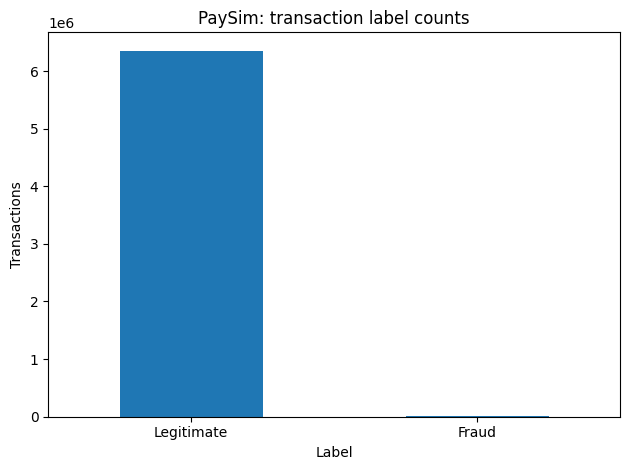

In [6]:
if paysim is not None:
    fraud_counts = paysim["isFraud"].value_counts().sort_index()
    fraud_pct = paysim["isFraud"].value_counts(normalize=True).sort_index() * 100
    display(pd.DataFrame({"count": fraud_counts, "percentage": fraud_pct.round(4)}))

    ax = fraud_counts.rename({0: "Legitimate", 1: "Fraud"}).plot(
        kind="bar", title="PaySim: transaction label counts"
    )
    ax.set_xlabel("Label")
    ax.set_ylabel("Transactions")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

,count
type,
CASH_OUT,2237500
PAYMENT,2151495
CASH_IN,1399284
TRANSFER,532909
DEBIT,41432


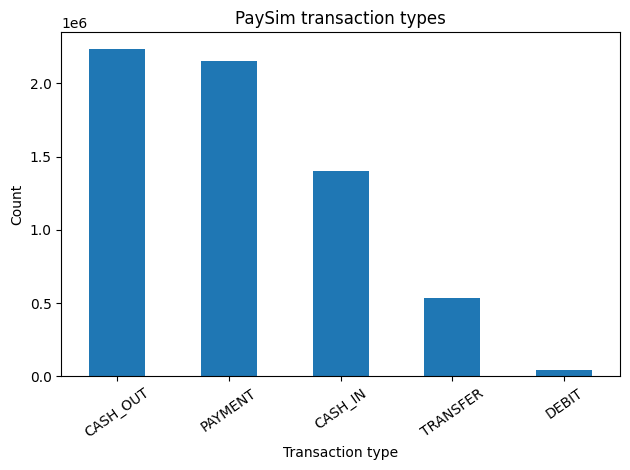

In [7]:
if paysim is not None:
    type_counts = paysim["type"].value_counts()
    display(type_counts.to_frame("count"))

    type_counts.plot(kind="bar", title="PaySim transaction types")
    plt.xlabel("Transaction type")
    plt.ylabel("Count")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

,Legitimate_%,Fraud_%
type,,
CASH_IN,100.000,0.000
CASH_OUT,99.816,0.184
DEBIT,100.000,0.000
PAYMENT,100.000,0.000
TRANSFER,99.231,0.769


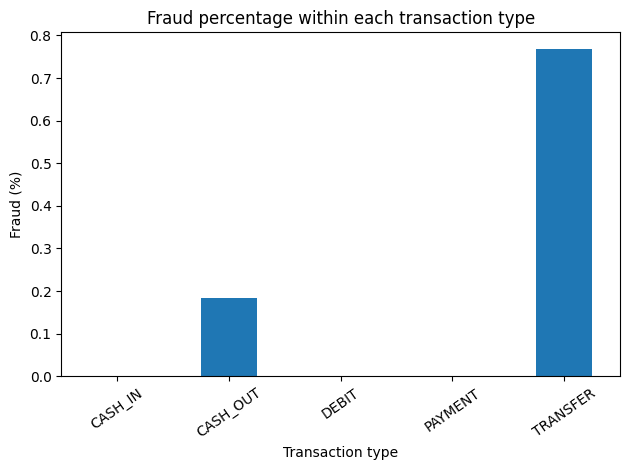

In [8]:
if paysim is not None:
    fraud_by_type = pd.crosstab(paysim["type"], paysim["isFraud"], normalize="index") * 100
    fraud_by_type.columns = ["Legitimate_%", "Fraud_%"]
    display(fraud_by_type.round(3))

    fraud_by_type[["Fraud_%"]].plot(
        kind="bar", legend=False, title="Fraud percentage within each transaction type"
    )
    plt.ylabel("Fraud (%)")
    plt.xlabel("Transaction type")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

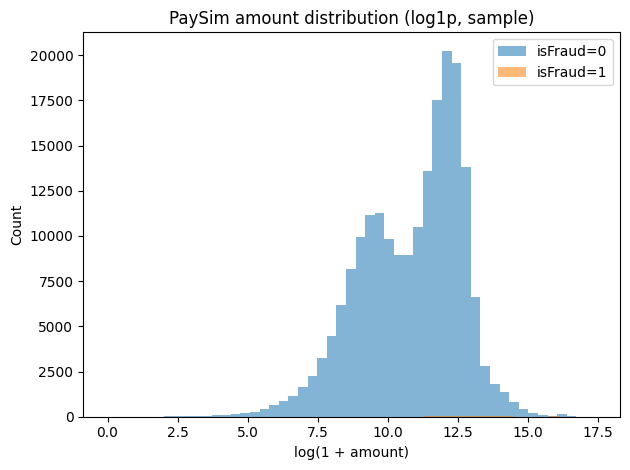

In [9]:
if paysim is not None:
    # Amounts are usually heavily skewed. Use a log scale for readability.
    sample = paysim.sample(min(200_000, len(paysim)), random_state=RANDOM_STATE)
    for label, group in sample.groupby("isFraud"):
        plt.hist(
            np.log1p(group["amount"].clip(lower=0)),
            bins=50, alpha=0.55, label=f"isFraud={label}"
        )
    plt.title("PaySim amount distribution (log1p, sample)")
    plt.xlabel("log(1 + amount)")
    plt.ylabel("Count")
    plt.legend()
    plt.tight_layout()
    plt.show()

### 3.1 PaySim modelling cautions

- Do not use account IDs as ordinary numeric values.
- Do not assume the simulator's fraud behaviour covers social engineering.
- Do not use balance-before/after fields in the initial model; cancelled fraud transactions can make these fields misleading.
- `isFlaggedFraud` is a pre-existing flag/rule outcome. Do not use it as an input if the aim is to independently predict fraud; it can leak an existing detection decision.
- Preserve the severe class imbalance when evaluating. Accuracy alone is not useful.
- For later modelling, consider a time-aware split using `step`, rather than randomly mixing all time steps.

## 5. Generate synthetic communication data (Dataset A)

This dataset is designed specifically for 3nSendi's social-engineering detection task. It contains both SMS and call-transcript records.

The labels describe the **scripted communication scenario**, not verified real-world incidents. Include legitimate messages that mention words such as OTP, account, support and transaction so the detector cannot rely on single keywords alone.

The initial categories are:
- authority impersonation
- urgency
- threat/loss
- reward/refund manipulation
- credential request
- secrecy
- legitimate service communication
- ordinary personal communication

This is a starter dataset for pipeline development. Before any serious model evaluation, expand it with diverse examples, Ghanaian phrasing, Twi-English code-switching reviewed by fluent speakers, typos, and independent test examples.

In [10]:
synthetic_messages = [
    # Fraudulent / social engineering examples
    ("SMS", "Your MoMo account will be suspended today. Call this number immediately to restore access.", 1, ["authority_impersonation", "urgency", "threat"]),
    ("SMS", "MTN MoMo support: send the OTP we just sent you to reverse the failed transaction.", 1, ["authority_impersonation", "credential_request"]),
    ("SMS", "Congratulations! You have won GHc 5000. Pay a small processing fee to receive your prize.", 1, ["reward_manipulation", "financial_request"]),
    ("SMS", "Your refund is pending. Transfer GHc 20 to this number to release your money now.", 1, ["refund_manipulation", "urgency", "financial_request"]),
    ("SMS", "Do not tell anyone about this account verification. Send your PIN to avoid losing your wallet.", 1, ["secrecy", "credential_request", "threat"]),
    ("CALL_TRANSCRIPT", "I am calling from the mobile money department. Your wallet has a problem. Read the OTP to me so I can secure it.", 1, ["authority_impersonation", "threat", "credential_request"]),
    ("CALL_TRANSCRIPT", "You must act in the next five minutes or your account will be blocked. Confirm the code on your screen.", 1, ["urgency", "threat", "credential_request"]),
    ("CALL_TRANSCRIPT", "I sent money to you by mistake. Please reverse it to this different number immediately.", 1, ["refund_manipulation", "urgency", "financial_request"]),
    ("SMS", "Your account is selected for a cash reward. Dial this code and follow the instructions to claim.", 1, ["reward_manipulation", "action_instruction"]),
    ("CALL_TRANSCRIPT", "I am an agent. Do not disconnect. I need you to approve the prompt so I can cancel the transaction.", 1, ["authority_impersonation", "urgency", "credential_request"]),

    # Legitimate examples, including sensitive vocabulary in safe contexts
    ("SMS", "Your MoMo transaction of GHc 45.00 was successful. Thank you for using the service.", 0, ["transaction_notification"]),
    ("SMS", "Never share your PIN or OTP with anyone, including people claiming to be customer support.", 0, ["security_advice"]),
    ("SMS", "Your monthly statement is ready. Sign in through the official app to view your transactions.", 0, ["account_notification"]),
    ("CALL_TRANSCRIPT", "Thank you for contacting customer support. We will never ask you to disclose your PIN or OTP.", 0, ["legitimate_support"]),
    ("CALL_TRANSCRIPT", "I am calling to confirm whether you received the payment notification. You do not need to share any code.", 0, ["legitimate_confirmation"]),
    ("SMS", "Your payment to the merchant was completed. Reference number 123456.", 0, ["transaction_notification"]),
    ("SMS", "For help with your wallet, use the customer care number published on the provider's official website.", 0, ["safe_support_guidance"]),
    ("CALL_TRANSCRIPT", "Please open the official application and check the transaction history. I will wait while you verify it.", 0, ["legitimate_support"]),
    ("SMS", "Your one-time password is for your sign-in. Do not share it with anyone.", 0, ["security_notification"]),
    ("SMS", "Your account profile was updated successfully. Contact support through official channels if this was not you.", 0, ["account_notification"])
]

base_comm = pd.DataFrame(
    synthetic_messages,
    columns=["event_type", "text", "is_social_engineering", "scenario_tags"]
)

# Create controlled variations without changing the underlying label.
# These variations are intentionally simple; add human-reviewed variety later.
def vary_text(text, rng):
    variants = [
        text,
        text.lower(),
        text.replace("GHc", "GHS"),
        text.replace("immediately", "right away"),
    ]
    return variants[int(rng.integers(0, len(variants)))]

comm_rows = []
for i in range(300):
    row = base_comm.iloc[i % len(base_comm)]
    comm_rows.append({
        "communication_id": f"COMM{i+1:04d}",
        "user_id": f"USER{int(rng.integers(1, 81)):03d}",
        "event_type": row["event_type"],
        "sender_number": f"024{int(rng.integers(1000000, 9999999))}",
        "timestamp": pd.Timestamp("2026-10-01") + pd.Timedelta(minutes=int(rng.integers(0, 60*24*30))),
        "text": vary_text(row["text"], rng),
        "is_social_engineering": int(row["is_social_engineering"]),
        "scenario_tags": "|".join(row["scenario_tags"]),
        "data_origin": "synthetic_scripted"
    })

synthetic_communication = pd.DataFrame(comm_rows)
display(synthetic_communication.head())
print("Shape:", synthetic_communication.shape)

,communication_id,user_id,event_type,sender_number,timestamp,text,is_social_engineering,scenario_tags,data_origin
0,COMM0001,USER008,SMS,0247965603,2026-10-20 15:17:00,your momo account will be suspended today. call this number immediately to restore access.,1,authority_impersonation|urgency|threat,synthetic_scripted
1,COMM0002,USER035,SMS,0248727380,2026-10-03 13:52:00,MTN MoMo support: send the OTP we just sent you to reverse the failed transaction.,1,authority_impersonation|credential_request,synthetic_scripted
2,COMM0003,USER017,SMS,0241847596,2026-10-16 19:03:00,Congratulations! You have won GHc 5000. Pay a small processing fee to receive your prize.,1,reward_manipulation|financial_request,synthetic_scripted
3,COMM0004,USER059,SMS,0247850256,2026-10-22 12:35:00,Your refund is pending. Transfer GHc 20 to this number to release your money now.,1,refund_manipulation|urgency|financial_request,synthetic_scripted
4,COMM0005,USER042,SMS,0242153022,2026-10-26 04:37:00,do not tell anyone about this account verification. send your pin to avoid losing your wallet.,1,secrecy|credential_request|threat,synthetic_scripted


Shape: (300, 9)


### 5.1 Communication data checks and EDA

,count
is_social_engineering,
social_engineering,150
legitimate,150


,count,mean,std,min,25%,50%,75%,max
is_social_engineering,,,,,,,,
0,150.0,91.70,13.250681,68.0,83.0,92.5,104.0,109.0
1,150.0,93.22,9.194301,81.0,87.0,92.0,99.0,112.0


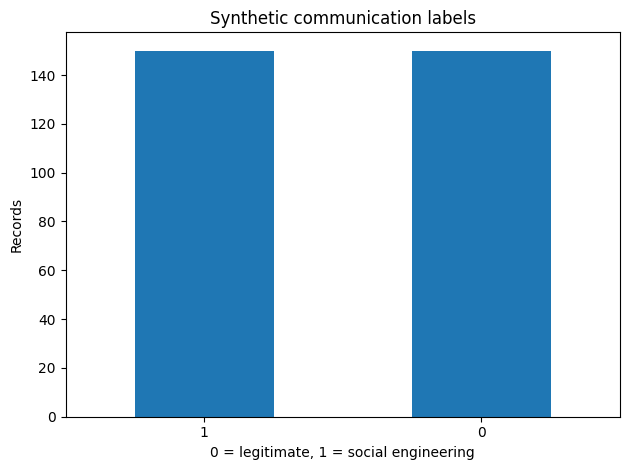

In [11]:
display(synthetic_communication["is_social_engineering"].value_counts().rename(
    index={0: "legitimate", 1: "social_engineering"}
).to_frame("count"))

synthetic_communication["text_length"] = synthetic_communication["text"].str.len()
display(synthetic_communication.groupby("is_social_engineering")["text_length"].describe())

synthetic_communication["is_social_engineering"].value_counts().plot(
    kind="bar", title="Synthetic communication labels"
)
plt.xlabel("0 = legitimate, 1 = social engineering")
plt.ylabel("Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Generate synthetic transaction-and-behaviour data (Dataset B)

This dataset represents a transaction together with contextual indicators from the user's recent activity.

It is not a copy of PaySim. It is a separate, purpose-built dataset for testing the event-correlation and transaction-risk components.

Important design rule: each feature must be observable **before** the transaction decision if it is to be used for pre-transaction detection. Do not include post-transaction outcomes as model inputs.

In [12]:
n_behaviour = 1000
behaviour_rows = []

for i in range(n_behaviour):
    is_fraud = int(rng.random() < 0.20)  # deliberately balanced enough for development tests

    if is_fraud:
        suspicious_sms = int(rng.random() < 0.78)
        suspicious_call = int(rng.random() < 0.68)
        credential_request = int(rng.random() < 0.55)
        new_recipient = int(rng.random() < 0.70)
        new_device = int(rng.random() < 0.22)
        recent_reported_number = int(rng.random() < 0.18)
        amount = float(np.round(rng.lognormal(mean=5.5, sigma=1.0), 2))
    else:
        suspicious_sms = int(rng.random() < 0.025)
        suspicious_call = int(rng.random() < 0.025)
        credential_request = int(rng.random() < 0.005)
        new_recipient = int(rng.random() < 0.18)
        new_device = int(rng.random() < 0.035)
        recent_reported_number = int(rng.random() < 0.003)
        amount = float(np.round(rng.lognormal(mean=4.5, sigma=0.9), 2))

    behaviour_rows.append({
        "transaction_id": f"TXN{i+1:05d}",
        "user_id": f"USER{int(rng.integers(1, 201)):03d}",
        "timestamp": pd.Timestamp("2026-10-01") + pd.Timedelta(minutes=int(rng.integers(0, 60*24*30))),
        "transaction_type": rng.choice(["TRANSFER", "PAYMENT", "CASH_OUT"], p=[0.55, 0.30, 0.15]),
        "amount": amount,
        "is_new_recipient": new_recipient,
        "recent_suspicious_sms": suspicious_sms,
        "recent_suspicious_call": suspicious_call,
        "credential_request_detected": credential_request,
        "new_device_recently": new_device,
        "recipient_recently_reported": recent_reported_number,
        "is_fraud_scenario": is_fraud,
        "data_origin": "synthetic_scripted"
    })

synthetic_behaviour = pd.DataFrame(behaviour_rows)
display(synthetic_behaviour.head())
print("Shape:", synthetic_behaviour.shape)

,transaction_id,user_id,timestamp,transaction_type,amount,is_new_recipient,recent_suspicious_sms,recent_suspicious_call,credential_request_detected,new_device_recently,recipient_recently_reported,is_fraud_scenario,data_origin
0,TXN00001,USER096,2026-10-25 06:38:00,PAYMENT,543.25,0,0,0,0,0,0,0,synthetic_scripted
1,TXN00002,USER089,2026-10-09 22:23:00,PAYMENT,20.36,0,0,0,0,0,0,0,synthetic_scripted
2,TXN00003,USER009,2026-10-17 05:05:00,CASH_OUT,51.17,0,0,0,0,0,0,0,synthetic_scripted
3,TXN00004,USER161,2026-10-01 05:50:00,PAYMENT,134.52,1,0,0,0,0,0,0,synthetic_scripted
4,TXN00005,USER174,2026-10-16 22:02:00,TRANSFER,51.54,0,0,0,0,1,0,0,synthetic_scripted


Shape: (1000, 13)


### 6.1 Behaviour dataset EDA

In [13]:
display(synthetic_behaviour.describe(include="all").T)
display(synthetic_behaviour.isna().sum().to_frame("missing_values"))

display(synthetic_behaviour["is_fraud_scenario"].value_counts().rename(
    index={0: "legitimate", 1: "fraud scenario"}
).to_frame("count"))

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
transaction_id,1000,1000,TXN00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user_id,1000,199,USER031,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,1000,NaN,NaN,NaN,2026-10-15 18:55:01.680000,2026-10-01 01:21:00,2026-10-08 02:35:30,2026-10-15 13:30:30,2026-10-23 10:58:00,2026-10-30 21:16:00,NaN
transaction_type,1000,3,TRANSFER,536,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,1000.0,NaN,NaN,NaN,172.26262,1.73,53.0125,102.635,195.4825,5877.31,272.922691
is_new_recipient,1000.0,NaN,NaN,NaN,0.289,0.0,0.0,0.0,1.0,1.0,0.453525
recent_suspicious_sms,1000.0,NaN,NaN,NaN,0.165,0.0,0.0,0.0,0.0,1.0,0.371366
recent_suspicious_call,1000.0,NaN,NaN,NaN,0.154,0.0,0.0,0.0,0.0,1.0,0.361129
credential_request_detected,1000.0,NaN,NaN,NaN,0.128,0.0,0.0,0.0,0.0,1.0,0.334257
new_device_recently,1000.0,NaN,NaN,NaN,0.076,0.0,0.0,0.0,0.0,1.0,0.265131


,missing_values
transaction_id,0
user_id,0
timestamp,0
transaction_type,0
amount,0
is_new_recipient,0
recent_suspicious_sms,0
recent_suspicious_call,0
credential_request_detected,0
new_device_recently,0


,count
is_fraud_scenario,
legitimate,802
fraud scenario,198


is_fraud_scenario,Legitimate scenario rate,Fraud scenario rate
is_new_recipient,0.190,0.692
recent_suspicious_sms,0.026,0.727
recent_suspicious_call,0.021,0.692
credential_request_detected,0.012,0.596
new_device_recently,0.037,0.232
recipient_recently_reported,0.000,0.157


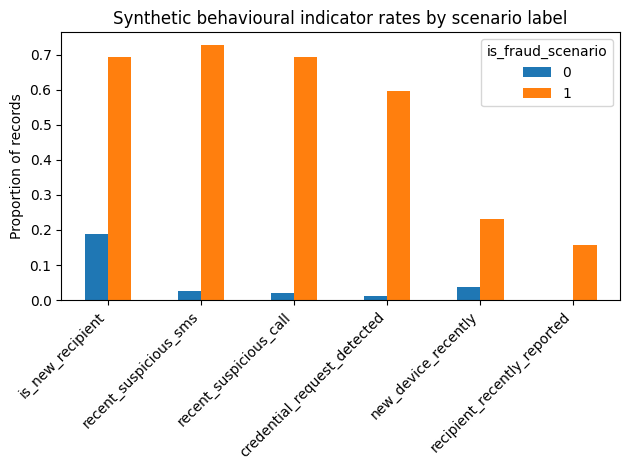

In [14]:
behaviour_cols = [
    "is_new_recipient", "recent_suspicious_sms", "recent_suspicious_call",
    "credential_request_detected", "new_device_recently",
    "recipient_recently_reported"
]
rate_by_label = synthetic_behaviour.groupby("is_fraud_scenario")[behaviour_cols].mean().T
display(rate_by_label.rename(columns={0: "Legitimate scenario rate", 1: "Fraud scenario rate"}).round(3))

rate_by_label.plot(kind="bar", title="Synthetic behavioural indicator rates by scenario label")
plt.ylabel("Proportion of records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

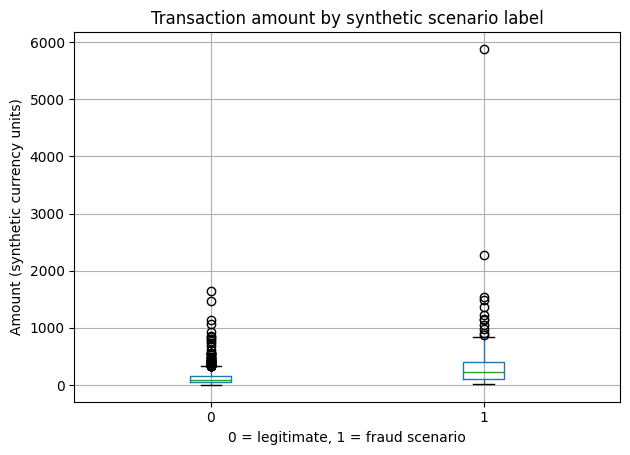

In [15]:
synthetic_behaviour.boxplot(column="amount", by="is_fraud_scenario")
plt.title("Transaction amount by synthetic scenario label")
plt.suptitle("")
plt.xlabel("0 = legitimate, 1 = fraud scenario")
plt.ylabel("Amount (synthetic currency units)")
plt.tight_layout()
plt.show()

## 7. Create an integrated event-sequence test dataset

This is the key end-to-end test asset for 3nSendi.

Each `scenario_id` represents one simulated user journey. Events are ordered in time and linked by `user_id`. The integrated label is assigned at the **scenario/transaction level**, not copied from an SMS spam label.

The starter scenarios below cover:
- fake account-suspension message → impersonation call → OTP request → transfer
- fake refund message → call → transfer
- legitimate service notification → ordinary transfer
- suspicious message without a subsequent transaction
- legitimate support interaction that explicitly warns users not to share credentials

The dataset is intentionally small and transparent. Expand it with more varied scenarios before using it for model evaluation.

In [16]:
scenario_templates = [
    {
        "name": "account_takeover_social_engineering",
        "fraud": 1,
        "events": [
            ("SMS", "Your wallet will be suspended. Call immediately to restore access.", -12),
            ("CALL_TRANSCRIPT", "I am from customer support. Read the OTP so I can secure your wallet.", -6),
            ("TRANSACTION", "Transfer initiated to an unfamiliar recipient.", 0)
        ]
    },
    {
        "name": "fake_refund",
        "fraud": 1,
        "events": [
            ("SMS", "A refund is waiting. Contact this number now to receive it.", -10),
            ("CALL_TRANSCRIPT", "Please reverse the payment to this different number immediately.", -4),
            ("TRANSACTION", "Transfer initiated to an unfamiliar recipient.", 0)
        ]
    },
    {
        "name": "legitimate_everyday_transfer",
        "fraud": 0,
        "events": [
            ("SMS", "Your previous transaction was successful. Thank you.", -20),
            ("TRANSACTION", "Transfer to a familiar recipient.", 0)
        ]
    },
    {
        "name": "suspicious_message_no_transaction",
        "fraud": 1,
        "events": [
            ("SMS", "Congratulations, you have won a cash prize. Pay a fee to claim.", 0)
        ]
    },
    {
        "name": "legitimate_security_advice",
        "fraud": 0,
        "events": [
            ("SMS", "Never share your PIN or OTP with anyone, including customer support.", -8),
            ("CALL_TRANSCRIPT", "Please check your transaction in the official app. We will never ask for your code.", -4),
            ("TRANSACTION", "Transfer to a familiar recipient.", 0)
        ]
    }
]

integrated_rows = []
for s_idx, scenario in enumerate(scenario_templates, start=1):
    scenario_id = f"SCN{s_idx:03d}"
    user_id = f"TESTUSER{s_idx:03d}"
    base_time = pd.Timestamp("2026-11-01 10:00:00")

    for event_idx, (event_type, description, minute_offset) in enumerate(scenario["events"], start=1):
        integrated_rows.append({
            "scenario_id": scenario_id,
            "user_id": user_id,
            "event_id": f"{scenario_id}_EV{event_idx:02d}",
            "event_type": event_type,
            "event_time": base_time + pd.Timedelta(minutes=minute_offset),
            "description": description,
            "is_transaction_event": int(event_type == "TRANSACTION"),
            "scenario_is_fraudulent": scenario["fraud"],
            "scenario_name": scenario["name"],
            "data_origin": "synthetic_integrated_test"
        })

integrated_test = pd.DataFrame(integrated_rows).sort_values(
    ["scenario_id", "event_time"]
).reset_index(drop=True)

display(integrated_test)
print("Scenarios:", integrated_test["scenario_id"].nunique())
print("Events:", len(integrated_test))

,scenario_id,user_id,event_id,event_type,event_time,description,is_transaction_event,scenario_is_fraudulent,scenario_name,data_origin
0,SCN001,TESTUSER001,SCN001_EV01,SMS,2026-11-01 09:48:00,Your wallet will be suspended. Call immediately to restore access.,0,1,account_takeover_social_engineering,synthetic_integrated_test
1,SCN001,TESTUSER001,SCN001_EV02,CALL_TRANSCRIPT,2026-11-01 09:54:00,I am from customer support. Read the OTP so I can secure your wallet.,0,1,account_takeover_social_engineering,synthetic_integrated_test
2,SCN001,TESTUSER001,SCN001_EV03,TRANSACTION,2026-11-01 10:00:00,Transfer initiated to an unfamiliar recipient.,1,1,account_takeover_social_engineering,synthetic_integrated_test
3,SCN002,TESTUSER002,SCN002_EV01,SMS,2026-11-01 09:50:00,A refund is waiting. Contact this number now to receive it.,0,1,fake_refund,synthetic_integrated_test
4,SCN002,TESTUSER002,SCN002_EV02,CALL_TRANSCRIPT,2026-11-01 09:56:00,Please reverse the payment to this different number immediately.,0,1,fake_refund,synthetic_integrated_test
5,SCN002,TESTUSER002,SCN002_EV03,TRANSACTION,2026-11-01 10:00:00,Transfer initiated to an unfamiliar recipient.,1,1,fake_refund,synthetic_integrated_test
6,SCN003,TESTUSER003,SCN003_EV01,SMS,2026-11-01 09:40:00,Your previous transaction was successful. Thank you.,0,0,legitimate_everyday_transfer,synthetic_integrated_test
7,SCN003,TESTUSER003,SCN003_EV02,TRANSACTION,2026-11-01 10:00:00,Transfer to a familiar recipient.,1,0,legitimate_everyday_transfer,synthetic_integrated_test
8,SCN004,TESTUSER004,SCN004_EV01,SMS,2026-11-01 10:00:00,"Congratulations, you have won a cash prize. Pay a fee to claim.",0,1,suspicious_message_no_transaction,synthetic_integrated_test
9,SCN005,TESTUSER005,SCN005_EV01,SMS,2026-11-01 09:52:00,"Never share your PIN or OTP with anyone, including customer support.",0,0,legitimate_security_advice,synthetic_integrated_test


Scenarios: 5
Events: 12


### 7.1 Inspect the integrated scenarios

For every scenario, inspect the event sequence and the expected scenario label. This is a manual sanity check before implementing the correlation engine.

Do not use the `scenario_is_fraudulent` label as an input feature. It is the expected outcome used only for testing.

In [17]:
for scenario_id, group in integrated_test.groupby("scenario_id"):
    print("\\n", scenario_id, "-", group["scenario_name"].iloc[0])
    print("Expected scenario fraud label:", group["scenario_is_fraudulent"].iloc[0])
    display(group[["event_time", "event_type", "description"]])

\n SCN001 - account_takeover_social_engineering
Expected scenario fraud label: 1


,event_time,event_type,description
0,2026-11-01 09:48:00,SMS,Your wallet will be suspended. Call immediately to restore access.
1,2026-11-01 09:54:00,CALL_TRANSCRIPT,I am from customer support. Read the OTP so I can secure your wallet.
2,2026-11-01 10:00:00,TRANSACTION,Transfer initiated to an unfamiliar recipient.


\n SCN002 - fake_refund
Expected scenario fraud label: 1


,event_time,event_type,description
3,2026-11-01 09:50:00,SMS,A refund is waiting. Contact this number now to receive it.
4,2026-11-01 09:56:00,CALL_TRANSCRIPT,Please reverse the payment to this different number immediately.
5,2026-11-01 10:00:00,TRANSACTION,Transfer initiated to an unfamiliar recipient.


\n SCN003 - legitimate_everyday_transfer
Expected scenario fraud label: 0


,event_time,event_type,description
6,2026-11-01 09:40:00,SMS,Your previous transaction was successful. Thank you.
7,2026-11-01 10:00:00,TRANSACTION,Transfer to a familiar recipient.


\n SCN004 - suspicious_message_no_transaction
Expected scenario fraud label: 1


,event_time,event_type,description
8,2026-11-01 10:00:00,SMS,"Congratulations, you have won a cash prize. Pay a fee to claim."


\n SCN005 - legitimate_security_advice
Expected scenario fraud label: 0


,event_time,event_type,description
9,2026-11-01 09:52:00,SMS,"Never share your PIN or OTP with anyone, including customer support."
10,2026-11-01 09:56:00,CALL_TRANSCRIPT,Please check your transaction in the official app. We will never ask for your code.
11,2026-11-01 10:00:00,TRANSACTION,Transfer to a familiar recipient.


## 8. Data-quality checks

Run these checks before exporting:
- required columns exist
- IDs are unique where expected
- timestamps parse correctly
- labels contain only expected values
- missing values are understood
- data origin is recorded

In [18]:
def basic_quality_report(df, name, id_col=None, label_col=None, check_duplicates=True):
    print(f"--- {name} ---")
    print("Rows, columns:", df.shape)
    if check_duplicates:
        print("Duplicate rows:", df.duplicated().sum())
    else:
        print("Full duplicate scan skipped for this large dataset.")
    print("Total missing cells:", int(df.isna().sum().sum()))
    if id_col and id_col in df.columns:
        print(f"Duplicate {id_col}:", int(df[id_col].duplicated().sum()))
    if label_col and label_col in df.columns:
        print("Label counts:")
        display(df[label_col].value_counts(dropna=False).to_frame("count"))

basic_quality_report(synthetic_communication, "Synthetic communication", "communication_id", "is_social_engineering")
basic_quality_report(synthetic_behaviour, "Synthetic behaviour", "transaction_id", "is_fraud_scenario")
basic_quality_report(integrated_test, "Integrated test events", "event_id", "scenario_is_fraudulent")
if paysim is not None:
    basic_quality_report(paysim, "PaySim", label_col="isFraud", check_duplicates=False)

--- Synthetic communication ---
Rows, columns: (300, 10)
Duplicate rows: 0
Total missing cells: 0
Duplicate communication_id: 0
Label counts:


,count
is_social_engineering,
1,150
0,150


--- Synthetic behaviour ---
Rows, columns: (1000, 13)
Duplicate rows: 0
Total missing cells: 0
Duplicate transaction_id: 0
Label counts:


,count
is_fraud_scenario,
0,802
1,198


--- Integrated test events ---
Rows, columns: (12, 10)
Duplicate rows: 0
Total missing cells: 0
Duplicate event_id: 0
Label counts:


,count
scenario_is_fraudulent,
1,7
0,5


--- PaySim ---
Rows, columns: (6362620, 11)
Full duplicate scan skipped for this large dataset.


Total missing cells: 0
Label counts:


,count
isFraud,
0,6354407
1,8213


## 9. Canonical dataset policy

The merged communication and transaction CSVs in `data/synthetic/` are the canonical workflow inputs. Keep their labels separate because their units of analysis differ. The integrated event CSV is a scenario fixture for correlation tests, not model training.

In [19]:
print(
    "EDA-generated samples remain in memory. The consolidated datasets in data/synthetic "
    "are the canonical inputs used by notebooks 02-07."
)

EDA-generated samples remain in memory. The consolidated datasets in data/synthetic are the canonical inputs used by notebooks 02-07.


## 10. Initial findings and decisions to record

Complete this section after running the notebook. Record:
1. PaySim class imbalance and which transaction types contain simulated fraud.
2. PaySim limitations and features excluded because of leakage risk.
4. Synthetic communication category coverage and gaps.
5. Synthetic behavioural feature distributions and whether the scripted patterns are too easy to distinguish.
6. Integrated scenarios that the event engine must detect.
7. Additional Ghana-specific examples requiring human review.

### Workflow notes

**Notebooks 02–07 — Feature Engineering, Detection & Evaluation**
- PaySim transaction feature engineering and time-aware split.
- Synthetic communication feature extraction.
- Behavioural feature preparation.
- Baseline models and evaluation with precision, recall, F1, PR-AUC and confusion matrices.
- Explicit separation between component-level model evaluation and integrated scenario testing.

### References
- PaySim Kaggle dataset and documentation: https://www.kaggle.com/datasets/ealaxi/paysim1
- PaySim paper: López-Rojas, E. A., Elmir, A., & Axelsson, S. (2016), *PaySim: A financial mobile money simulator for fraud detection*.

Check each dataset's licence and citation requirements before redistributing it or publishing results.